In [1]:
# Experiment No. 4: Linear Regression for Predictive Modeling

In [2]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [3]:
# Step 2: Load the dataset
df = pd.read_csv("Salary_Data.csv")

In [4]:
# Step 3: Display dataset
print("First Five Records:")
print(df.head())

First Five Records:
   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0


In [5]:
# Step 4: Check dataset information
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
None


In [6]:
# Step 5: Select independent and dependent variables
X = df[['YearsExperience']]
y = df['Salary']


In [7]:

# Step 6: Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [8]:
# Step 7: Create Linear Regression model
model = LinearRegression()


In [9]:
# Step 8: Train the model
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9423.82]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.532e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [10]:
# Step 9: Predict salary
y_pred = model.predict(X_test)

print("\nActual and Predicted Salary:")
results = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})
print(results)


Actual and Predicted Salary:
   Actual Salary  Predicted Salary
0       112635.0     115790.210113
1        67938.0      71498.278095
2       113812.0     102596.868661
3        83088.0      75267.804224
4        64445.0      55477.792045
5        57189.0      60189.699707


In [11]:
# Step 10: Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)


Model Evaluation:
Mean Absolute Error: 6286.453830757749
Mean Squared Error: 49830096.85590839
Root Mean Squared Error: 7059.04362190151
R2 Score: 0.9024461774180497


In [12]:

# Step 11: Display regression equation
print("\nRegression Equation:")
print("Salary =", model.intercept_, "+",
      model.coef_[0], "* YearsExperience")


Regression Equation:
Salary = 25321.583011776813 + 9423.815323030976 * YearsExperience


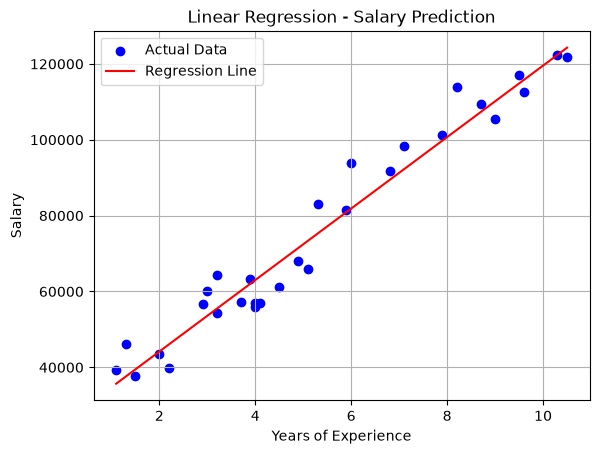

In [13]:
# Step 12: Visualize regression line
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, model.predict(X), color='red',
         label='Regression Line')

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression - Salary Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Step 13: Predict salary for new input
new_experience = pd.DataFrame({'YearsExperience': [5]})
predicted_salary = model.predict(new_experience)

print("\nPredicted Salary for 5 Years Experience:",
      predicted_salary[0])


Predicted Salary for 5 Years Experience: 72440.6596269317
